# 04 – Flooded land cover
ESA WorldCover 2020 (10 m, from Sentinel-1/-2; Zanaga et al. 2021) overlaid with the optical flood of 22 Apr (area per class) and the Sentinel-1 floods of 22 Apr – 16 May (persistence per class). WorldCover is one year after the event; the broad classes are stable in this farmland.

In [1]:
import ee
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

import common as c
import config as cfg

c.init()
aoi = c.study_area()
landcover = ee.ImageCollection(cfg.WORLDCOVER).first().select("Map").clip(aoi)
flood = c.optical_flood(cfg.L8_DURING, aoi)

## Flooded area per class (optical, 22 Apr)

In [2]:
total_per_class = c.area_per_class(ee.Image(1), landcover, aoi)
# classes < 1 km² give meaningless percentages
total_per_class = {value: km2 for value, km2 in total_per_class.items() if km2 >= 1}
flood_per_class = c.area_per_class(flood, landcover, aoi)

table = pd.DataFrame({
    "class": [cfg.WORLDCOVER_NAMES[value] for value in total_per_class],
    "area_km2": total_per_class.values(),
    "flooded_km2": [flood_per_class.get(value, 0.0) for value in total_per_class],
})
table["share_of_flood_%"] = 100 * table["flooded_km2"] / table["flooded_km2"].sum()
table["class_flooded_%"] = 100 * table["flooded_km2"] / table["area_km2"]
table = table.sort_values(by="flooded_km2", ascending=False).round(1).reset_index(drop=True)
table.to_csv(cfg.TABLES / "flooded_landcover.csv", index=False)
table

,class,area_km2,flooded_km2,share_of_flood_%,class_flooded_%
0,Cropland,3505.5,624.2,84.1,17.8
1,Grassland,517.6,86.0,11.6,16.6
2,Tree cover,123.4,16.3,2.2,13.2
3,Permanent water bodies,35.7,11.0,1.5,31.0
4,Bare / sparse vegetation,23.7,1.8,0.2,7.4
5,Herbaceous wetland,7.2,1.4,0.2,20.1
6,Built-up,37.2,1.2,0.2,3.3


`share_of_flood_%`: share of the total flood; `class_flooded_%`: share of the class under water.

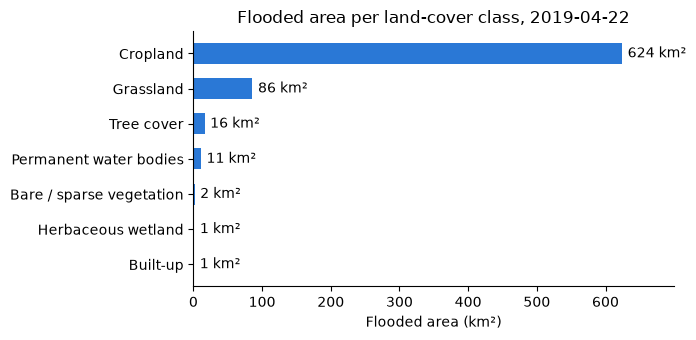

In [3]:
shown = table.loc[table["flooded_km2"] >= 0.5].sort_values(by="flooded_km2")

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(shown["class"], shown["flooded_km2"], color="#2a78d6", height=0.6)
ax.bar_label(bars, labels=[f"{km2:.0f} km²" for km2 in shown["flooded_km2"]], padding=4)
ax.set_xlabel("Flooded area (km²)")
ax.set_title(f"Flooded area per land-cover class, {cfg.L8_DURING}")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.12)
fig.tight_layout()
fig.savefig(cfg.FIGURES / "flooded_landcover_bar.png", dpi=200)

## Map: flooded areas by land-cover class

In [4]:
# remap class values (10, 20, ...) to palette indices
class_values = list(cfg.WORLDCOVER_COLORS)
class_palette = [cfg.WORLDCOVER_COLORS[value].lstrip("#") for value in class_values]
flooded_landcover = landcover.updateMask(flood).remap(class_values, list(range(len(class_values))))
landcover_colors = {"min": 0, "max": len(class_values) - 1, "palette": class_palette}

m = c.Map(center=(48.5, -97.1), zoom=9)
m.addLayer(landcover, {"bands": ["Map"]}, "ESA WorldCover 2020 (all)", False)
m.addLayer(flooded_landcover, landcover_colors, f"Flooded land cover {cfg.L8_DURING}")
m.add_legend(builtin_legend="ESA_WorldCover")
m

Map(center=[48.5, -97.1], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

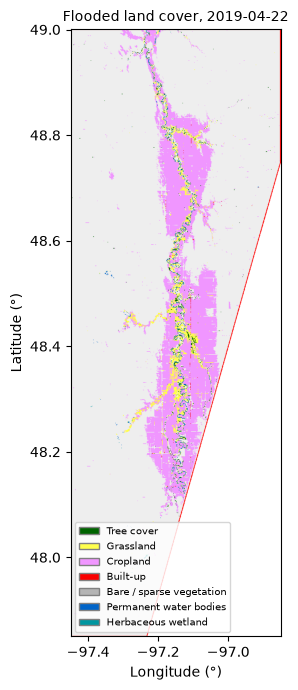

In [5]:
layer = (
    ee.Image(1).clip(aoi).visualize(palette=["eeeeee"])  # light grey = not flooded
    .blend(flooded_landcover.visualize(**landcover_colors))
    .blend(c.outline(aoi))
)
fig, ax = plt.subplots(figsize=(5, 7))
c.plot_map(ax, layer, aoi, f"Flooded land cover, {cfg.L8_DURING}")
names_shown = {name: cfg.WORLDCOVER_COLORS[value] for value, name in cfg.WORLDCOVER_NAMES.items() if name in set(shown["class"])}
ax.legend(handles=c.legend_patches(names_shown), loc="lower left", fontsize=7)
fig.tight_layout()
fig.savefig(cfg.FIGURES / "flooded_landcover_map.png", dpi=200)

## Persistence per class (Sentinel-1)
Share of each class flooded per date; the four largest land classes are plotted.

In [6]:
vh_before = c.sentinel1_vh_median(cfg.S1_BEFORE_WINDOW, aoi)

rows = []
for day in cfg.S1_TIMELINE:
    vh = c.sentinel1_vh_median(c.one_day(day), aoi)
    flooded = c.area_per_class(c.sar_flood(vh, vh_before), landcover, aoi)
    for value, area_km2 in total_per_class.items():
        rows.append({
            "date": day,
            "class": cfg.WORLDCOVER_NAMES[value],
            "flooded_km2": flooded.get(value, 0.0),
            "class_flooded_%": 100 * flooded.get(value, 0.0) / area_km2,
        })

retention = pd.DataFrame(rows).round(1)
retention.to_csv(cfg.TABLES / "flooded_landcover_timeline.csv", index=False)
retention.pivot(index="class", columns="date", values="class_flooded_%")

date,2019-04-22,2019-05-04,2019-05-16,2019-08-20
class,,,,
Bare / sparse vegetation,8.4,4.9,2.8,1.2
Built-up,7.2,2.1,1.1,0.2
Cropland,15.3,13.5,8.4,0.4
Grassland,12.4,9.0,1.7,1.9
Herbaceous wetland,20.8,11.4,2.6,5.9
Permanent water bodies,17.0,13.9,4.0,0.0
Tree cover,0.8,0.5,0.1,0.1


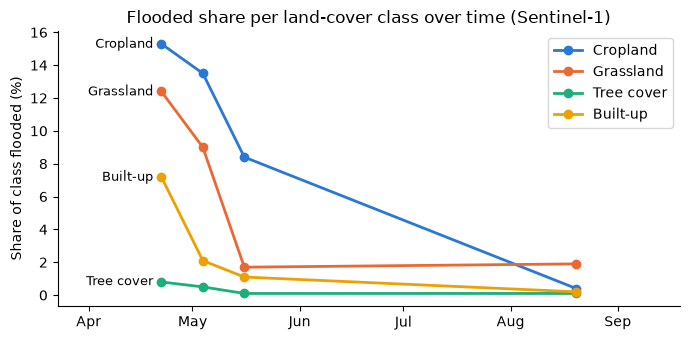

In [7]:
main_classes = ["Cropland", "Grassland", "Tree cover", "Built-up"]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, color in zip(main_classes, colors):
    rows = retention.loc[retention["class"] == name]
    ax.plot(pd.to_datetime(rows["date"]), rows["class_flooded_%"], marker="o", color=color, linewidth=2, label=name)
    first_point = (mdates.datestr2num(rows["date"].iloc[0]), rows["class_flooded_%"].iloc[0])
    ax.annotate(name, first_point, xytext=(-6, 0),
                textcoords="offset points", ha="right", va="center", fontsize=9)
ax.set_ylabel("Share of class flooded (%)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("Flooded share per land-cover class over time (Sentinel-1)")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(cfg.FIGURES / "flooded_landcover_timeline.png", dpi=200)

## Notes
- 22 Apr: cropland 624 km² (84 % of the flood), grassland 86 km² (12 %), tree cover 16 km² (2 %), built-up 1 km².
- Share of class flooded: cropland 18 %, grassland 17 %, tree cover 13 %, built-up 3 %. The study area is flat former lake bed of glacial Lake Agassiz, mostly cropland.
- Cropland keeps the water longest: 8.4 % still flooded on 16 May (55 % of the 22 Apr value), grassland 1.7 % (14 %), built-up 1.1 %. Flat, ditch-drained fields → shallow ponding; grassland is mostly riparian and drains back to the river.
- Tree cover: optical 13 % vs. SAR 0.8 %. Leaf-off trees in April let Landsat see the water; under trees, radar double bounce makes the signal brighter, so ratio change detection misses it.
- Built-up: SAR 7 % vs. optical 3 %; radar is unreliable between buildings, optical value preferred. Little built-up flooding: towns along the river are diked.
- Limitations: WorldCover 2020 vs. 2019 event; 10 m classes vs. 30 m flood; WorldCover overall accuracy ~75 % (Zanaga et al. 2021).